# Model evaluation with the implemented pipeline

\<write here on the implemented pipeline, current population features, validation design, and notebook setup>

In [1]:
from pathlib import Path
from water_wells import (DataConfig, DataLoader, TrainingConfig,
                         TrainingPipeline, ModelEvaluator)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
loader = DataLoader(DataConfig(data_dir=ROOT))
X, y = loader.load_training()
X.shape, y.value_counts()

((59400, 40),
 status_group
 functional                 32259
 non functional             22824
 functional needs repair     4317
 Name: count, dtype: int64)

In [2]:
X.columns

Index(['id', 'amount_tsh', 'date_recorded', 'funder', 'gps_height',
       'installer', 'longitude', 'latitude', 'wpt_name', 'num_private',
       'basin', 'subvillage', 'region', 'region_code', 'district_code', 'lga',
       'ward', 'population', 'public_meeting', 'recorded_by',
       'scheme_management', 'scheme_name', 'permit', 'construction_year',
       'extraction_type', 'extraction_type_group', 'extraction_type_class',
       'management', 'management_group', 'payment', 'payment_type',
       'water_quality', 'quality_group', 'quantity', 'quantity_group',
       'source', 'source_type', 'source_class', 'waterpoint_type',
       'waterpoint_type_group'],
      dtype='str')

## Split raw data, then fit
Only training rows fit the geographic reference, imputers, encoders, and model. The original notebook used 500 estimators and a 25% validation fraction.

In [3]:
config = TrainingConfig(model_path=ROOT / "models/water_well_model.joblib")
pipeline = TrainingPipeline(
    config,
    population_raster=ROOT / "tza_pop_2026_CN_1km_R2025A_UA_v1.tif",
    cache_dir=ROOT / "data/processed/population",
    data_mode="auto",
)
holdout_regions = ["Morogoro"]
X_train, X_valid, X_holdout, y_train, y_valid, y_holdout = pipeline.split(X, y, holdout_regions=holdout_regions)
pipeline.fit(X_train, y_train)

,config,TrainingConfi...'n_jobs': -1})
,population_raster,PosixPath('/U...5A_UA_v1.tif')
,cache_dir,PosixPath('/U...d/population')
,data_mode,'auto'
Name,Type,Value
classes_,"ndarray[object](3,)","['functional','functional needs repair','non functional']"
label_encoder_,LabelEncoder,LabelEncoder()
pipeline_,Pipeline,"Pipeline(step...ass=3, ...))])"


## Validation metrics

In [4]:
evaluator = ModelEvaluator()
predictions = pipeline.predict(X_valid)
evaluator.metrics(y_valid, predictions)

{'accuracy': 0.7942811755361397,
 'precision': 0.7938975853192084,
 'recall': 0.7942811755361397,
 'f1': 0.7816878162678277}

## Random and majority baselines

In [5]:
import pandas as pd

# Use the same held-out rows as XGBoost; fit baselines on training labels only.
random_predictions = evaluator.baseline_predictions(
    X_train, y_train, X_valid,
    strategy="stratified", random_state=config.random_seed,
)
majority_predictions = evaluator.baseline_predictions(
    X_train, y_train, X_valid, strategy="most_frequent",
)
comparison_df = pd.DataFrame.from_dict({
    "xgboost": evaluator.metrics(y_valid, predictions),
    "random_baseline": evaluator.metrics(y_valid, random_predictions),
    "majority_baseline": evaluator.metrics(y_valid, majority_predictions),
}, orient="index")
comparison_df


,accuracy,precision,recall,f1
xgboost,0.794281,0.793898,0.794281,0.781688
random_baseline,0.456495,0.455862,0.456495,0.456178
majority_baseline,0.544083,0.296026,0.544083,0.383433


## Geographic holdout evaluation

In [6]:
from IPython.display import display
import pandas as pd

# Evaluate the unseen geographic region separately from validation.
holdout_results_df = pipeline.predict_wells(X_holdout)
holdout_results_df["actual_status"] = y_holdout
holdout_results_df["region"] = X_holdout["region"]
holdout_predictions = holdout_results_df["predicted_status"]
holdout_metrics_df = pd.DataFrame(
    [evaluator.metrics(y_holdout, holdout_predictions)],
    index=["geographic_holdout"],
)
display(holdout_metrics_df)
print(evaluator.classification_report(y_holdout, holdout_predictions))
holdout_results_df.head()


                         precision    recall  f1-score   support

             functional       0.74      0.79      0.76      2119
functional needs repair       0.00      0.00      0.00       300
         non functional       0.69      0.76      0.72      1587

               accuracy                           0.72      4006
              macro avg       0.48      0.52      0.50      4006
           weighted avg       0.66      0.72      0.69      4006



,accuracy,precision,recall,f1
geographic_holdout,0.717923,0.664483,0.717923,0.690133


,id,latitude,longitude,predicted_status,probability_functional,probability_needs_repair,probability_non_functional,actual_status,region
70,21990,-8.934950,35.818981,functional,0.489509,0.034490,0.476001,non functional,Morogoro
81,65531,-7.024263,37.722953,functional,0.538706,0.071578,0.389716,functional needs repair,Morogoro
116,21068,-6.829501,37.487474,non functional,0.453337,0.031414,0.515249,functional,Morogoro
141,60852,-6.771699,37.823462,functional,0.681906,0.057476,0.260618,functional,Morogoro
143,17687,-6.299767,37.443110,non functional,0.117604,0.020291,0.862105,functional,Morogoro


## Classification reports and confusion matrices

In [7]:
print(evaluator.classification_report(y_valid, predictions))
evaluator.confusion_matrix(y_valid, predictions)

                         precision    recall  f1-score   support

             functional       0.77      0.92      0.84      7535
functional needs repair       0.63      0.25      0.35      1004
         non functional       0.86      0.71      0.78      5310

               accuracy                           0.79     13849
              macro avg       0.75      0.63      0.66     13849
           weighted avg       0.79      0.79      0.78     13849



,functional,functional needs repair,non functional
functional,6958,86,491
functional needs repair,626,248,130
non functional,1456,60,3794


In [8]:
print(evaluator.classification_report(y_valid, random_predictions))
evaluator.confusion_matrix(y_valid, random_predictions)

                         precision    recall  f1-score   support

             functional       0.55      0.55      0.55      7535
functional needs repair       0.07      0.07      0.07      1004
         non functional       0.40      0.40      0.40      5310

               accuracy                           0.46     13849
              macro avg       0.34      0.34      0.34     13849
           weighted avg       0.46      0.46      0.46     13849



,functional,functional needs repair,non functional
functional,4137,572,2826
functional needs repair,548,73,383
non functional,2861,337,2112


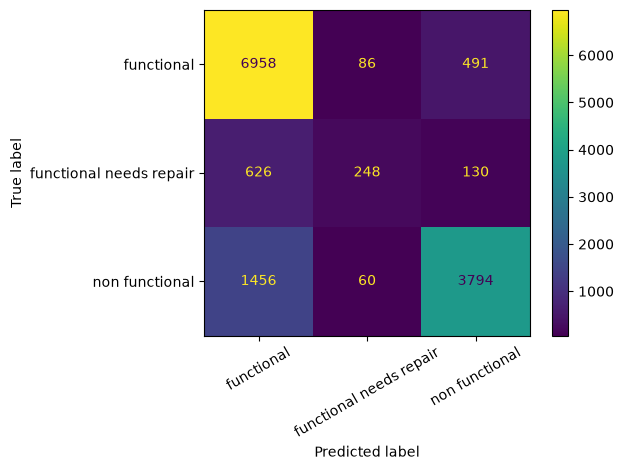

In [9]:
evaluator.plot_confusion_matrix(y_valid, predictions);

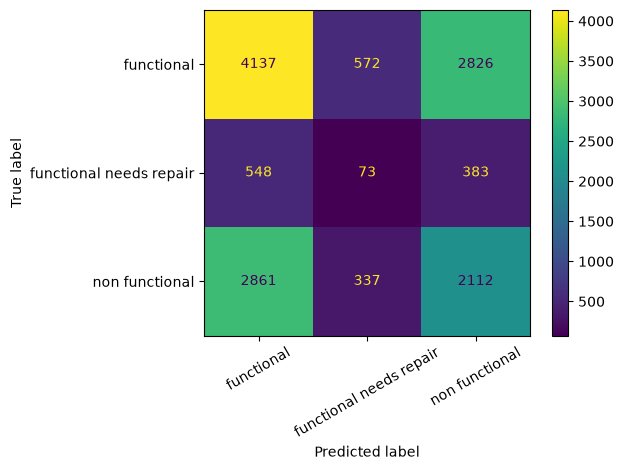

In [10]:
evaluator.plot_confusion_matrix(y_valid, random_predictions);

## Current feature importance

,feature,importance
0,other_categorical__waterpoint_type_group_other,0.042121
1,other_categorical__quantity_group_dry,0.041380
2,other_categorical__quantity_dry,0.037135
3,other_categorical__lga_Kigoma Rural,0.027068
4,other_categorical__waterpoint_type_other,0.026962
...,...,...
490,other_categorical__waterpoint_type_infrequent_...,0.000000
491,installer__installer_FW,0.000000
492,installer__installer_Handeni Trunk Main(,0.000000
493,installer__installer_KKKT _ Konde and DWE,0.000000


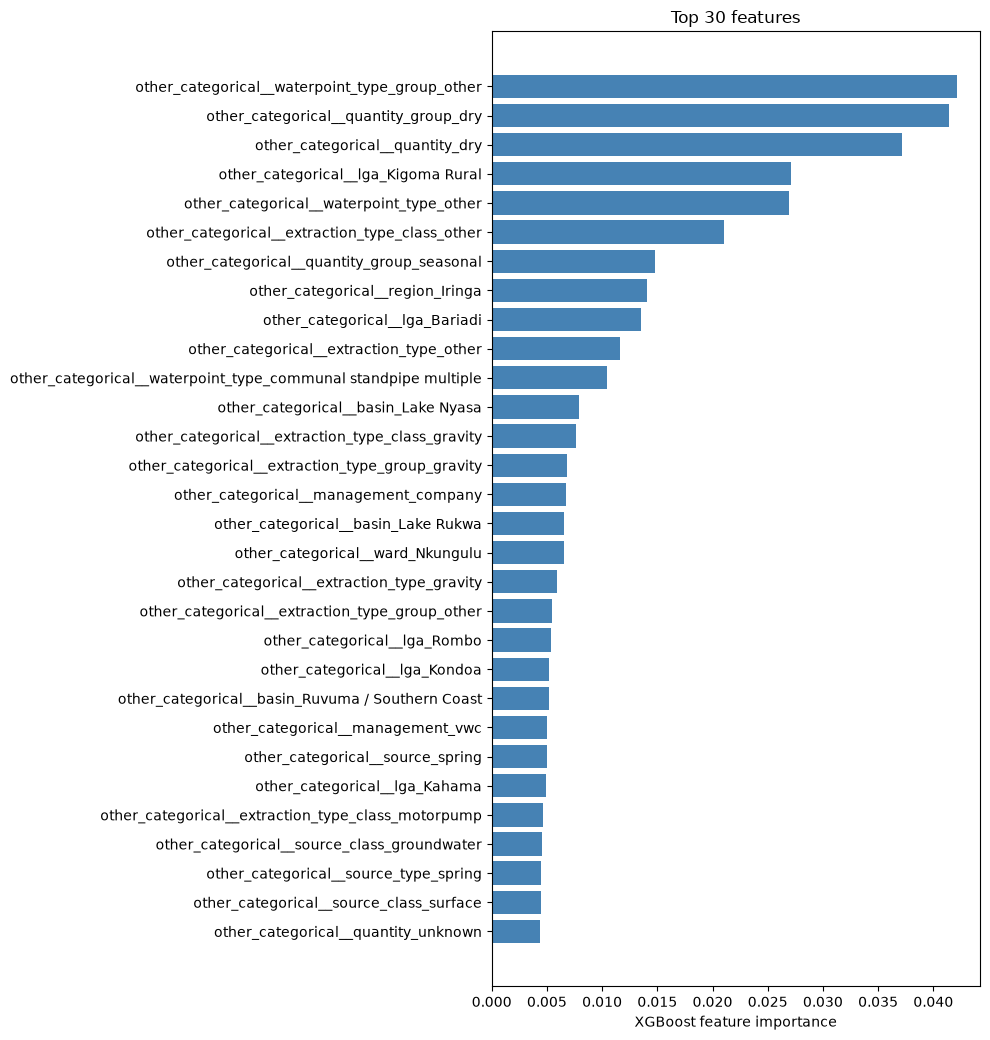

In [11]:
feature_importance_df = evaluator.feature_importance(pipeline)
display(feature_importance_df)
evaluator.plot_feature_importance(pipeline, top_n=30);

## Prediction probabilities and well identifiers

In [12]:
pipeline.predict_proba(X_valid.head())

,functional,functional needs repair,non functional
11019,0.757729,0.050473,0.191797
21275,0.845777,0.040424,0.113799
38751,0.981597,0.007440,0.010963
51120,0.693422,0.172909,0.133669
29555,0.152095,0.027699,0.820206


In [13]:
pipeline.predict_wells(X_valid.head())

,id,latitude,longitude,predicted_status,probability_functional,probability_needs_repair,probability_non_functional
11019,41403,-2.632290,33.436176,functional,0.757729,0.050473,0.191797
21275,60155,-3.385470,36.939347,functional,0.845777,0.040424,0.113799
38751,31843,-7.967611,35.047038,functional,0.981597,0.007440,0.010963
51120,9901,-9.207012,33.588892,functional,0.693422,0.172909,0.133669
29555,9499,-3.248534,37.601232,non functional,0.152095,0.027699,0.820206


## Save and reload
Load serialized artifacts only from trusted sources. This saves the training-split model; fit a fresh pipeline on all labeled rows after finalizing your experiment to make a final inference artifact.

In [14]:
pipeline.save()
restored = TrainingPipeline.load(config.model_path)
assert (restored.predict(X_valid.head()) == pipeline.predict(X_valid.head())).all()

## New unlabeled wells
Use the original feature schema. `predict_wells` preserves IDs, row order, index, and raw coordinates.

In [15]:
# new_wells = loader.load_features("data/raw/test_values.csv")
# results = restored.predict_wells(new_wells)
# results.to_csv(ROOT / "data/processed/predictions.csv", index=False)

## Cross-validation
`TrainingPipeline` is sklearn compatible. Every fold fits its own spatial reference and encoder; use raw features and readable target labels.

In [16]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
import pandas as pd

# Geographic holdout stays outside every cross-validation fold.
X_cv = pd.concat([X_train, X_valid])
y_cv = pd.concat([y_train, y_valid])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=config.random_seed)
scores = cross_val_score(clone(pipeline), X_cv, y_cv, cv=cv, scoring="accuracy")

In [17]:
scores

array([0.79057677, 0.79642567, 0.78910312])